# Imports

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from sklearn.preprocessing import MinMaxScaler
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import kpss
import pymannkendall as mk
from scipy.stats import kruskal
import warnings
warnings.filterwarnings("ignore")


# Data Visualization

In [2]:
df_consumo = pd.read_excel("data/consumption.xlsx", decimal=",")
df_consumo["Date"] = pd.to_datetime(df_consumo["Date"], format="%m/%Y")
df_consumo.set_index("Date", inplace=True)

targets = ["Residential (MWh)", "Industrial (MWh)", "Commercial (MWh)", "Other (MWh)"]

scalers = {}

def plot_targets(df, sufix):
    fig, ax = plt.subplots(figsize=(8, 5))
    for target in targets:
        ax.plot(df.index, df[target], label=target)

    ax.set_xlabel("Year", fontsize=14, fontweight='bold')
    ax.set_ylabel("Consumption (MWh)", fontsize=14, fontweight='bold')

    ax.tick_params(axis='both', which='major', labelsize=12)

    ax.ticklabel_format(style="plain", axis="y")
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{x:,.1f}"))

    plt.xticks(rotation=90)

    ax.grid(True, linestyle="--", alpha=0.6)

    plt.legend(fontsize=12)

    plt.tight_layout()
    plt.savefig(f"data/consumption{sufix}.png")
    plt.show()


## Paraná

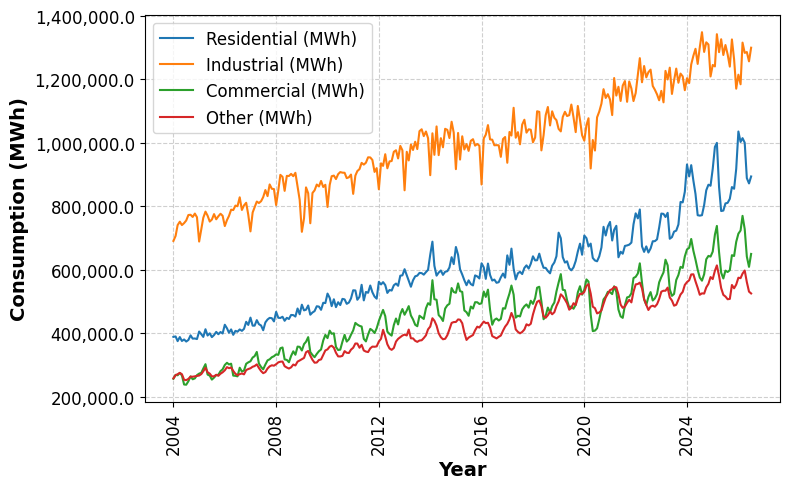

In [3]:
df_pr = df_consumo[df_consumo["State"] == "PR"]
plot_targets(df_pr, "_PR")

### Normalized

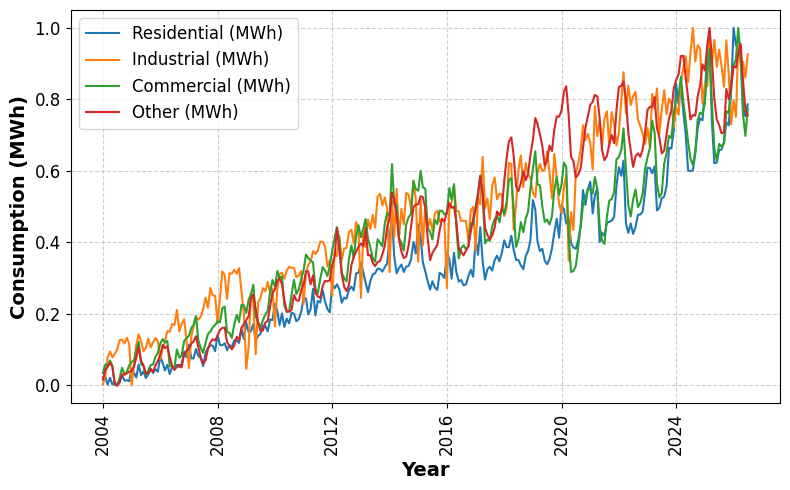

In [4]:
df_pr_norm = df_pr.copy()
for target in targets:
    scaler = MinMaxScaler()
    df_pr_norm[[target]] = scaler.fit_transform(df_pr[[target]])
    scalers[("PR", target)] = scaler

plot_targets(df_pr_norm,"_PR_minMax")

## Santa Catarina

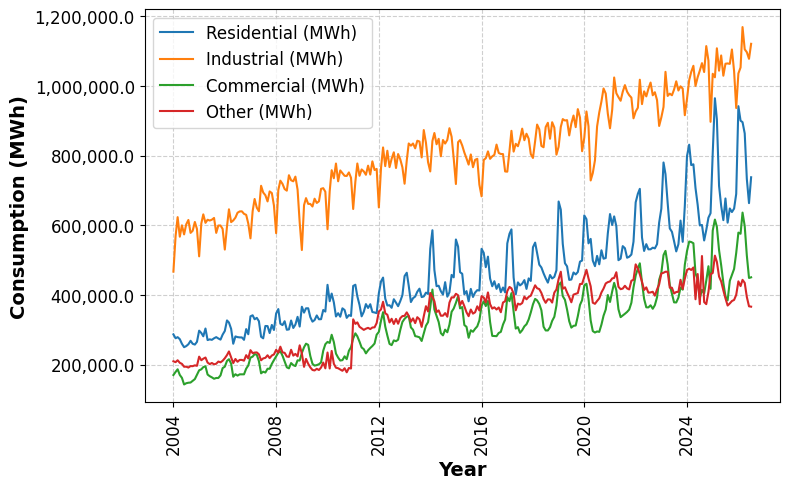

In [5]:
df_sc = df_consumo[df_consumo["State"] == "SC"]
plot_targets(df_sc, "_SC")

### Normalized

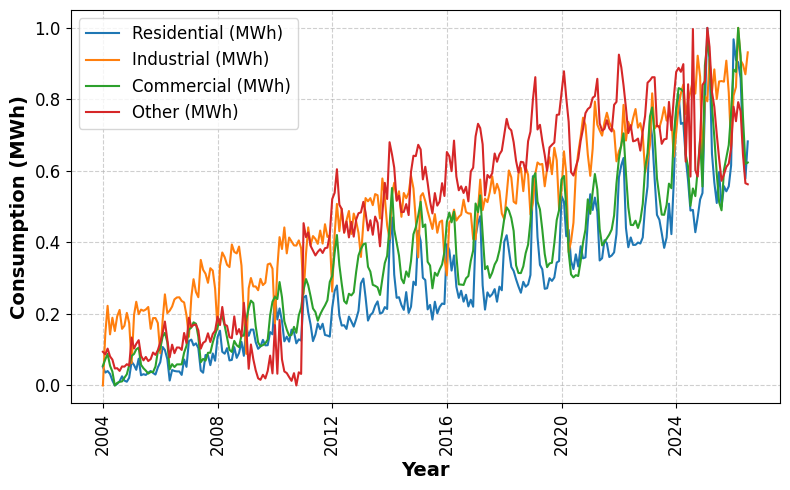

In [6]:
df_sc_norm = df_sc.copy()
for target in targets:
    scaler = MinMaxScaler()
    df_sc_norm[[target]] = scaler.fit_transform(df_sc[[target]])
    scalers[("SC", target)] = scaler

plot_targets(df_sc_norm,"_SC_minMax")

## Rio Grande do Sul

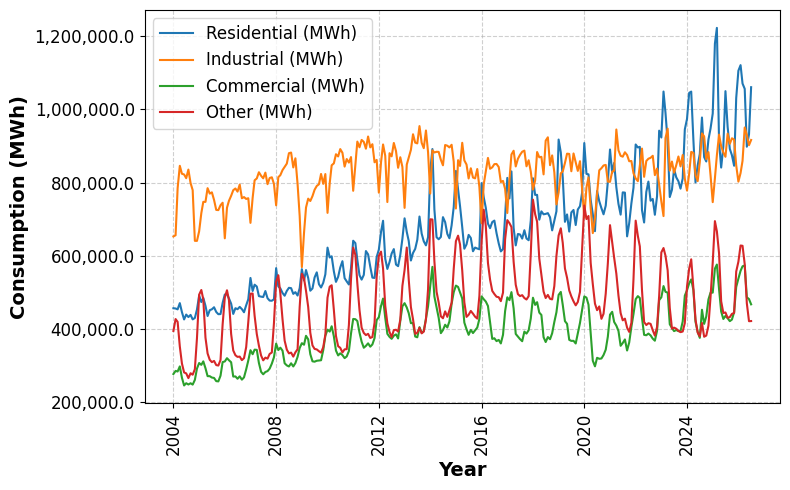

In [7]:
df_rs = df_consumo[df_consumo["State"] == "RS"]
plot_targets(df_rs, "_RS")

### Normalized

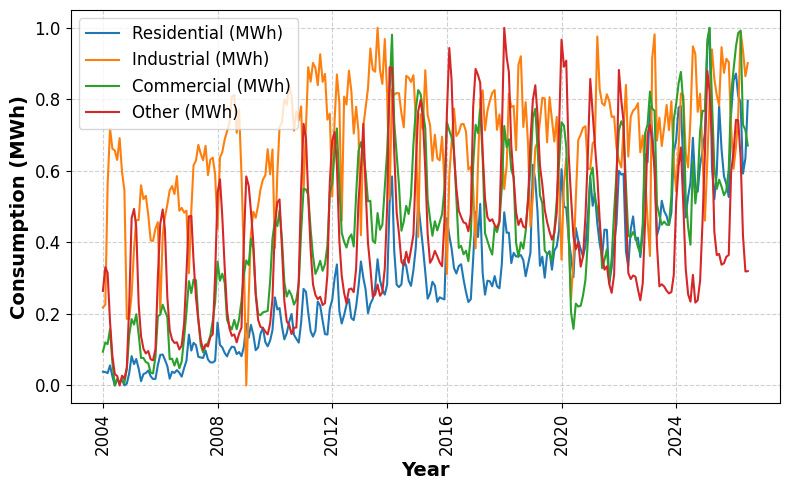

In [8]:
df_rs_norm = df_rs.copy()
for target in targets:
    scaler = MinMaxScaler()
    df_rs_norm[[target]] = scaler.fit_transform(df_rs[[target]])
    scalers[("RS", target)] = scaler

plot_targets(df_rs_norm, "_RS_minMax")

# Statistical Summary

In [9]:
def plot_acf_pacf(df_state, state_name, lags=12):
    fig, axes = plt.subplots(nrows=len(targets), ncols=2, figsize=(14, 3 * len(targets)))
    
    for i, target in enumerate(targets):
        serie = df_state[target].dropna()
        
        # ACF
        plot_acf(serie, ax=axes[i, 0], lags=lags, alpha=0.05, title=f"ACF - {target} ({state_name})")
        axes[i, 0].set_xlabel("Lag (Meses)", fontsize=11, fontweight="bold")
        axes[i, 0].set_ylabel("ACF", fontsize=11, fontweight="bold")
        axes[i, 0].set_xticks(range(0, lags + 1, 6))
        axes[i, 0].grid(True, linestyle="--", alpha=0.6)
        
        # PACF
        plot_pacf(serie, ax=axes[i, 1], lags=lags, alpha=0.05, method="ywm", title=f"PACF - {target} ({state_name})")
        axes[i, 1].set_xlabel("Lag (Meses)", fontsize=11, fontweight="bold")
        axes[i, 1].set_ylabel("PACF", fontsize=11, fontweight="bold")
        axes[i, 1].set_xticks(range(0, lags + 1, 6))
        axes[i, 1].grid(True, linestyle="--", alpha=0.6)
        
    plt.tight_layout()
    plt.savefig(f"data/acf_pacf_{state_name}.png", dpi=300, bbox_inches="tight")
    plt.show()

def run_hypothesis_tests(df_state, state_name):
    rows = []
    for target in targets:
        serie = df_state[target].dropna()
        
        # 1. KPSS Test (Estacionariedade)
        # H0: A série é estacionária | H1: A série tem raiz unitária (não-estacionária)
        kpss_stat, kpss_p, _, _ = kpss(serie, regression="c", nlags="auto")
        kpss_concl = "Stationary" if kpss_p >= 0.05 else "No stationarity"
        kpss_p_str = "<= 0.01" if kpss_p <= 0.01 else (">= 0.10" if kpss_p >= 0.10 else f"{kpss_p:.4f}")
        
        # 2. Mann-Kendall Test (Tendência)
        # H0: Sem tendência monotônica | H1: Presença de tendência monotônica
        mk_res = mk.original_test(serie)
        if mk_res.p < 0.05:
            mk_concl = "Crescent Trend" if mk_res.Tau > 0 else "Decrescent Trend"
        else:
            mk_concl = "No trend"
        mk_p_str = f"{mk_res.p:.2e}" if mk_res.p < 0.001 else f"{mk_res.p:.4f}"
        
        # 3. Kruskal-Wallis Test (Sazonalidade Mensal)
        # H0: Medianas dos 12 meses são iguais (Não-Sazonal) | H1: Ao menos dois meses diferem (Sazonal)
        monthly_groups = [group.values for _, group in serie.groupby(serie.index.month)]
        kw_stat, kw_p = kruskal(*monthly_groups)
        kw_concl = "Seazonal" if kw_p < 0.05 else "No seasonal"
        kw_p_str = f"{kw_p:.2e}" if kw_p < 0.001 else f"{kw_p:.4f}"
        
        rows.append({
            "State": state_name,
            "Consumo": target,
            "KPSS Stat": np.round(kpss_stat, 4),
            "KPSS p-valor": kpss_p_str,
            "KPSS Conclusão (alpha=0.05)": kpss_concl,
            "MK Tau": np.round(mk_res.Tau, 4),
            "MK Sen Slope": np.round(mk_res.slope, 2),
            "MK p-valor": mk_p_str,
            "MK Conclusão (alpha=0.05)": mk_concl,
            "KW Stat": np.round(kw_stat, 4),
            "KW p-valor": kw_p_str,
            "KW Conclusão (alpha=0.05)": kw_concl
        })
        
    df_res = pd.DataFrame(rows)
    df_res.set_index(["State", "Consumo"], inplace=True)
    return df_res

resumo_list = []

for state in df_consumo["State"].unique():
    df_state = df_consumo[df_consumo["State"] == state]
    
    for target in targets:
        serie = df_state[target]
        resumo_list.append({
            "State": state,
            "Consumption": target,
            "Frequency": "Monthly",
            "Data Points": int(serie.count()),
            "Mean": np.round(serie.mean(),2),
            "Standard Deviation": np.round(serie.std(),2),
            "Min": serie.min(),
            "Max": serie.max(),
        })

df_resumo = pd.DataFrame(resumo_list)
df_resumo.set_index(["State", "Consumption"], inplace=True)
df_resumo.to_csv("data/statistical_summary.csv")

display(df_resumo)


Frequency  Data Points        Mean  \
State Consumption                                            
PR    Residential (MWh)   Monthly          271   598186.28   
      Industrial (MWh)    Monthly          271  1001844.63   
      Commercial (MWh)    Monthly          271   456049.79   
      Other (MWh)         Monthly          271   413128.51   
SC    Residential (MWh)   Monthly          271   456532.93   
      Industrial (MWh)    Monthly          271   813566.84   
      Commercial (MWh)    Monthly          271   316238.40   
      Other (MWh)         Monthly          271   336780.63   
RS    Residential (MWh)   Monthly          271   675594.62   
      Industrial (MWh)    Monthly          271   829059.13   
      Commercial (MWh)    Monthly          271   390734.87   
      Other (MWh)         Monthly          271   470230.27   

                         Standard Deviation     Min      Max  
State Consumption                                             
PR    Residential (MWh)           147738.09  374402  1036149  
      Industrial (MWh)            164340.59  689452  1348993  
      Commercial (MWh)            117443.71  238401   770380  
      Other (MWh)                  98209.41  252785   614318  
SC    Residential (MWh)           147013.88  249891   964376  
      Industrial (MWh)            146382.49  466790  1168631  
      Commercial (MWh)            105927.65  142886   636167  
      Other (MWh)                  93097.22  177855   512640  
RS    Residential (MWh)           167767.26  425987  1222330  
      Industrial (MWh)             66049.70  568855   954097  
      Commercial (MWh)             75465.14  245687   575937  
      Other (MWh)                 108906.64  265760   753217

## Paraná

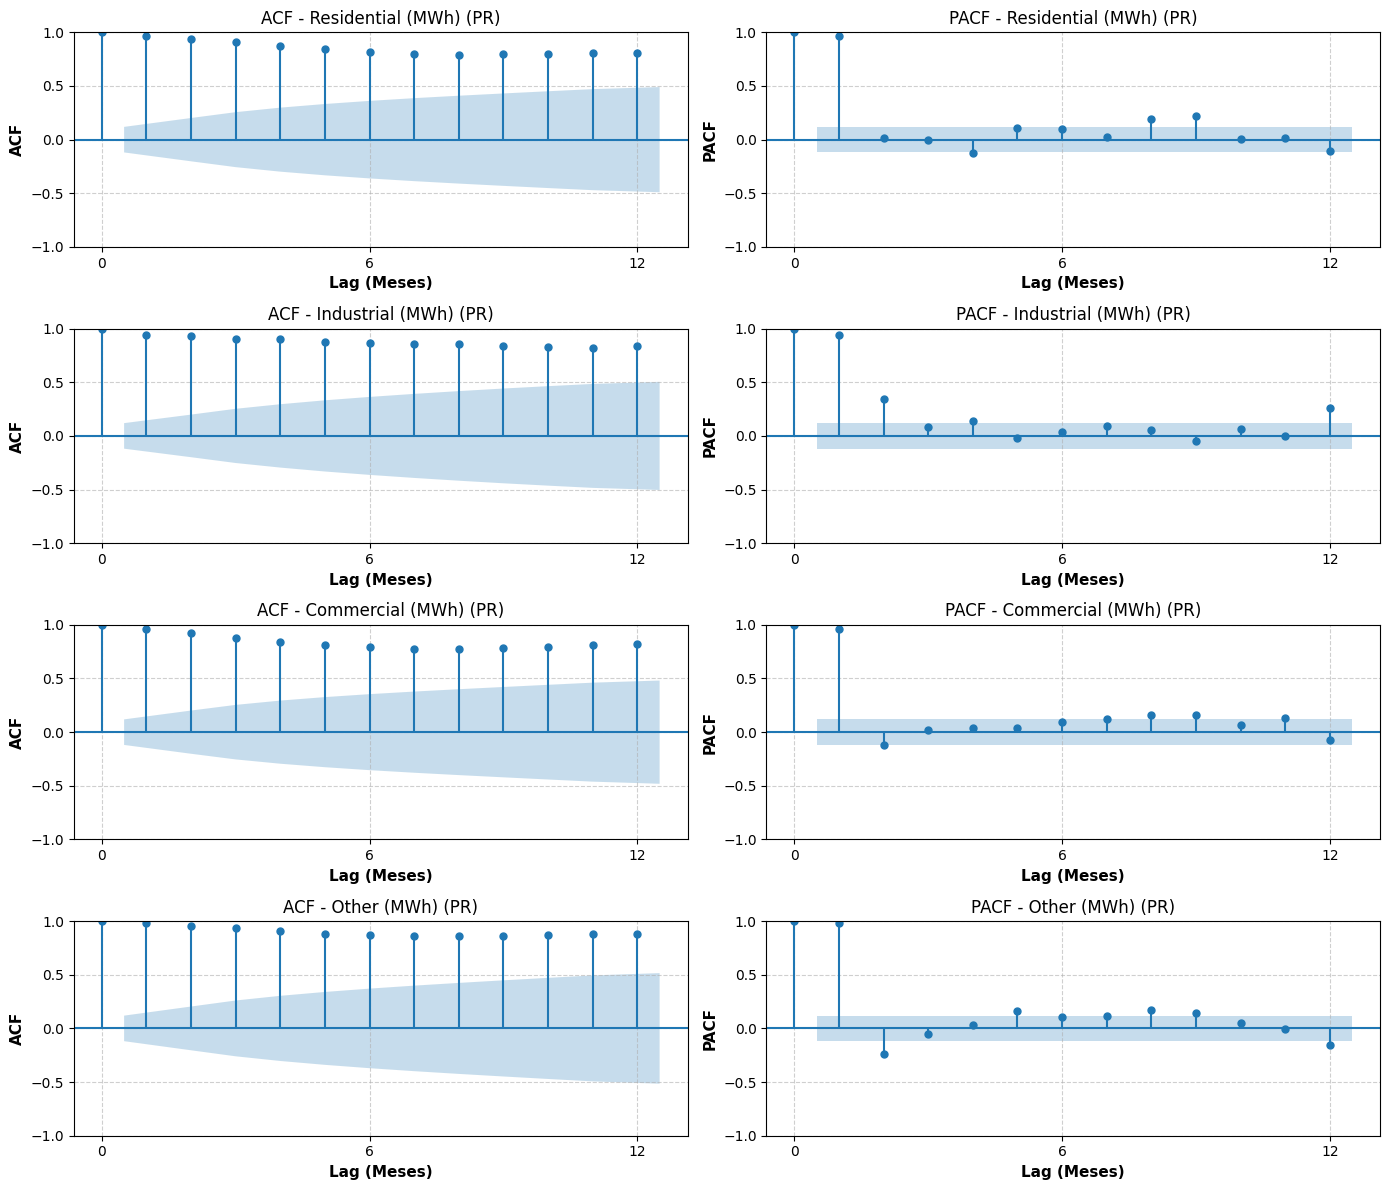

KPSS Stat KPSS p-valor KPSS Conclusão (alpha=0.05)  \
State Consumo                                                                 
PR    Residential (MWh)     2.3799      <= 0.01             No stationarity   
      Industrial (MWh)      2.4715      <= 0.01             No stationarity   
      Commercial (MWh)      2.3689      <= 0.01             No stationarity   
      Other (MWh)           2.5345      <= 0.01             No stationarity   

                         MK Tau  MK Sen Slope MK p-valor  \
State Consumo                                              
PR    Residential (MWh)  0.8699       1676.98   0.00e+00   
      Industrial (MWh)   0.8397       2012.07   0.00e+00   
      Commercial (MWh)   0.7879       1417.04   0.00e+00   
      Other (MWh)        0.8506       1207.25   0.00e+00   

                        MK Conclusão (alpha=0.05)  KW Stat KW p-valor  \
State Consumo                                                           
PR    Residential (MWh)            Crescent Trend   4.1715     0.9646   
      Industrial (MWh)             Crescent Trend   5.1207     0.9252   
      Commercial (MWh)             Crescent Trend  14.7889     0.1924   
      Other (MWh)                  Crescent Trend   8.8590     0.6349   

                        KW Conclusão (alpha=0.05)  
State Consumo                                      
PR    Residential (MWh)               No seasonal  
      Industrial (MWh)                No seasonal  
      Commercial (MWh)                No seasonal  
      Other (MWh)                     No seasonal

In [10]:
plot_acf_pacf(df_pr, state_name="PR", lags=12)
df_tests_pr = run_hypothesis_tests(df_pr, state_name="PR")
display(df_tests_pr)


## Santa Catarina

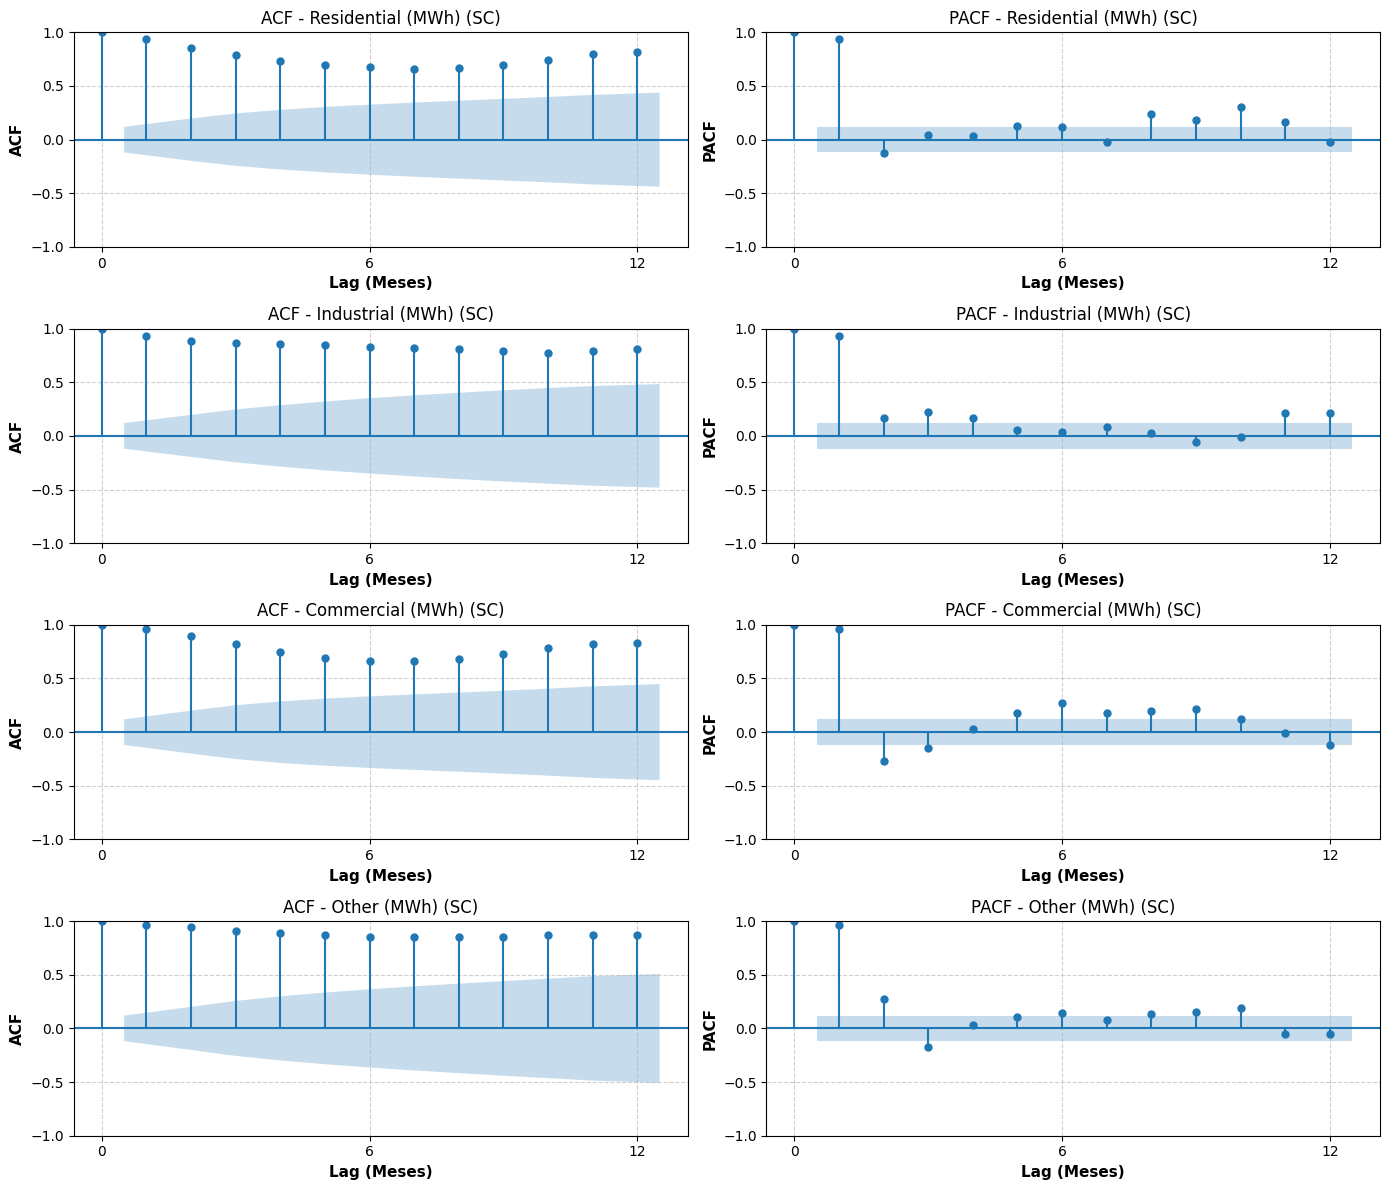

KPSS Stat KPSS p-valor KPSS Conclusão (alpha=0.05)  \
State Consumo                                                                 
SC    Residential (MWh)     2.4308      <= 0.01             No stationarity   
      Industrial (MWh)      2.4512      <= 0.01             No stationarity   
      Commercial (MWh)      2.4284      <= 0.01             No stationarity   
      Other (MWh)           2.3333      <= 0.01             No stationarity   

                         MK Tau  MK Sen Slope MK p-valor  \
State Consumo                                              
SC    Residential (MWh)  0.8082       1444.02   0.00e+00   
      Industrial (MWh)   0.8121       1772.75   0.00e+00   
      Commercial (MWh)   0.7725       1162.41   0.00e+00   
      Other (MWh)        0.6956       1084.98   0.00e+00   

                        MK Conclusão (alpha=0.05)  KW Stat KW p-valor  \
State Consumo                                                           
SC    Residential (MWh)            Crescent Trend  16.5189     0.1229   
      Industrial (MWh)             Crescent Trend  10.3009     0.5035   
      Commercial (MWh)             Crescent Trend  23.4523     0.0153   
      Other (MWh)                  Crescent Trend  16.4591     0.1249   

                        KW Conclusão (alpha=0.05)  
State Consumo                                      
SC    Residential (MWh)               No seasonal  
      Industrial (MWh)                No seasonal  
      Commercial (MWh)                   Seazonal  
      Other (MWh)                     No seasonal

In [11]:
plot_acf_pacf(df_sc, state_name="SC", lags=12)
df_tests_sc = run_hypothesis_tests(df_sc, state_name="SC")
display(df_tests_sc)


## Rio Grande do Sul

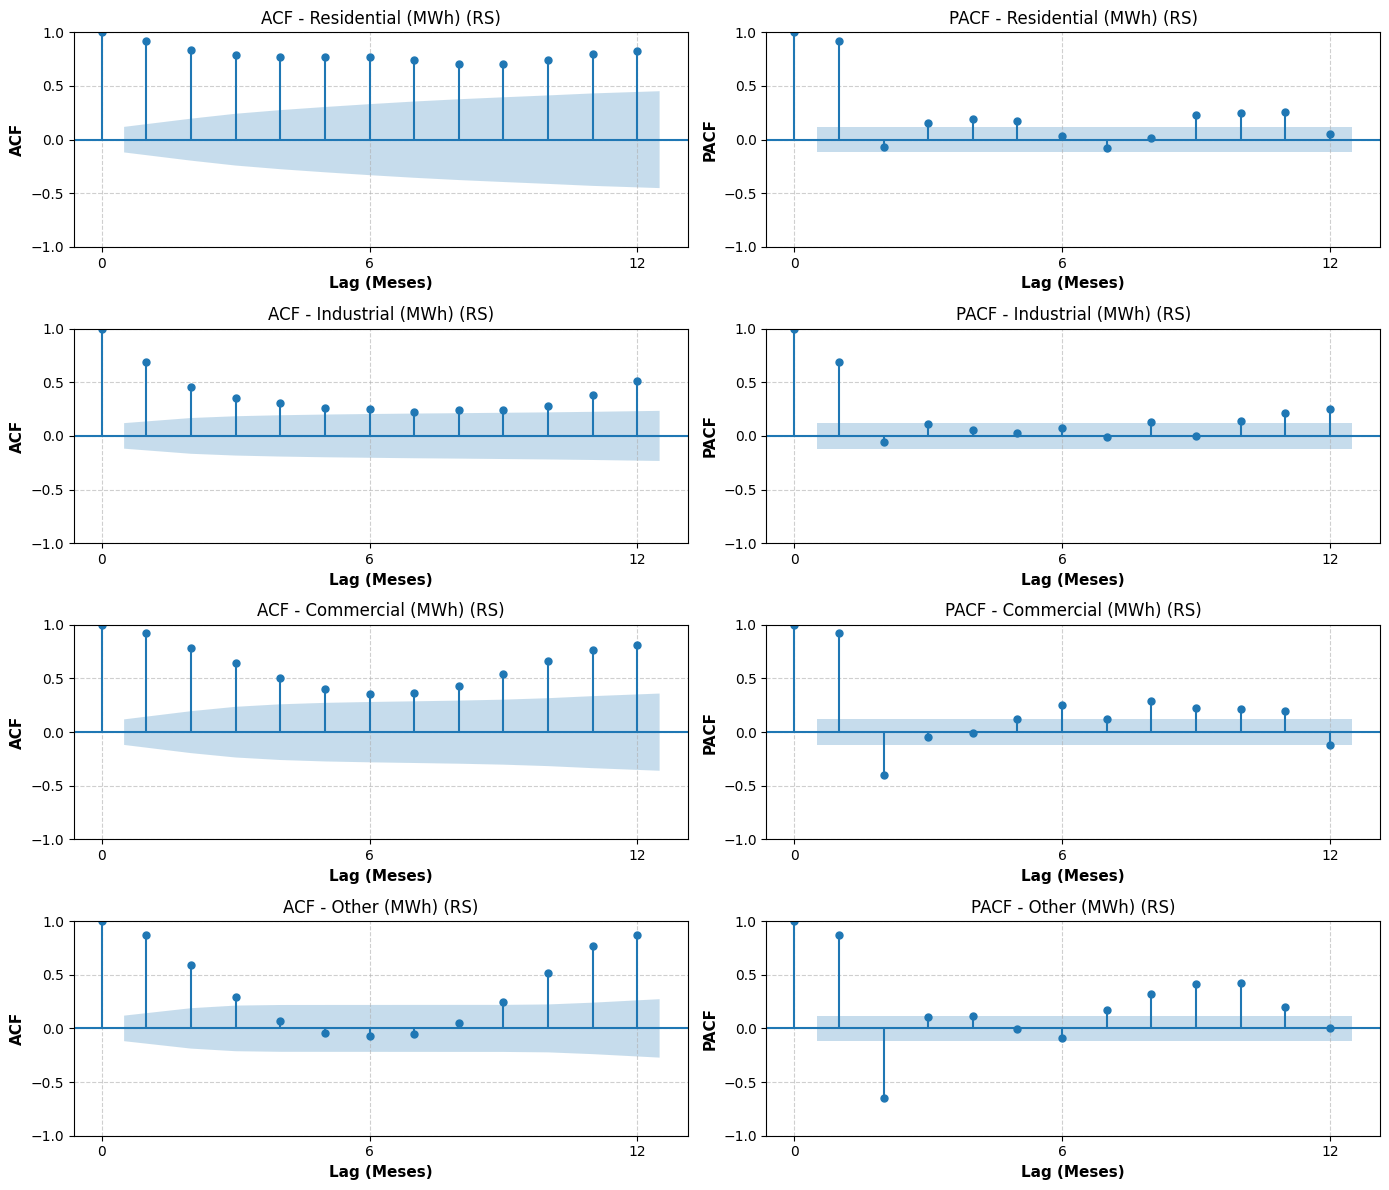

KPSS Stat KPSS p-valor KPSS Conclusão (alpha=0.05)  \
State Consumo                                                                 
RS    Residential (MWh)     2.4380      <= 0.01             No stationarity   
      Industrial (MWh)      1.0898      <= 0.01             No stationarity   
      Commercial (MWh)      2.0165      <= 0.01             No stationarity   
      Other (MWh)           1.7421      <= 0.01             No stationarity   

                         MK Tau  MK Sen Slope MK p-valor  \
State Consumo                                              
RS    Residential (MWh)  0.7942       1789.47   0.00e+00   
      Industrial (MWh)   0.2609        319.87   1.54e-10   
      Commercial (MWh)   0.5225        707.49   0.00e+00   
      Other (MWh)        0.3161        635.80   8.88e-15   

                        MK Conclusão (alpha=0.05)   KW Stat KW p-valor  \
State Consumo                                                            
RS    Residential (MWh)            Crescent Trend   16.4373     0.1257   
      Industrial (MWh)             Crescent Trend   73.4519   2.68e-11   
      Commercial (MWh)             Crescent Trend   65.7117   7.92e-10   
      Other (MWh)                  Crescent Trend  144.6782   1.82e-25   

                        KW Conclusão (alpha=0.05)  
State Consumo                                      
RS    Residential (MWh)               No seasonal  
      Industrial (MWh)                   Seazonal  
      Commercial (MWh)                   Seazonal  
      Other (MWh)                        Seazonal

In [12]:
plot_acf_pacf(df_rs, state_name="RS", lags=12)
df_tests_rs = run_hypothesis_tests(df_rs, state_name="RS")
display(df_tests_rs)


## Testes Compilados

In [14]:

df_tests_all = pd.concat([df_tests_pr, df_tests_sc, df_tests_rs])
df_tests_all.to_csv("data/hypothesis_tests_all.csv")
df_tests_all

KPSS Stat KPSS p-valor KPSS Conclusão (alpha=0.05)  \
State Consumo                                                                 
PR    Residential (MWh)     2.3799      <= 0.01             No stationarity   
      Industrial (MWh)      2.4715      <= 0.01             No stationarity   
      Commercial (MWh)      2.3689      <= 0.01             No stationarity   
      Other (MWh)           2.5345      <= 0.01             No stationarity   
SC    Residential (MWh)     2.4308      <= 0.01             No stationarity   
      Industrial (MWh)      2.4512      <= 0.01             No stationarity   
      Commercial (MWh)      2.4284      <= 0.01             No stationarity   
      Other (MWh)           2.3333      <= 0.01             No stationarity   
RS    Residential (MWh)     2.4380      <= 0.01             No stationarity   
      Industrial (MWh)      1.0898      <= 0.01             No stationarity   
      Commercial (MWh)      2.0165      <= 0.01             No stationarity   
      Other (MWh)           1.7421      <= 0.01             No stationarity   

                         MK Tau  MK Sen Slope MK p-valor  \
State Consumo                                              
PR    Residential (MWh)  0.8699       1676.98   0.00e+00   
      Industrial (MWh)   0.8397       2012.07   0.00e+00   
      Commercial (MWh)   0.7879       1417.04   0.00e+00   
      Other (MWh)        0.8506       1207.25   0.00e+00   
SC    Residential (MWh)  0.8082       1444.02   0.00e+00   
      Industrial (MWh)   0.8121       1772.75   0.00e+00   
      Commercial (MWh)   0.7725       1162.41   0.00e+00   
      Other (MWh)        0.6956       1084.98   0.00e+00   
RS    Residential (MWh)  0.7942       1789.47   0.00e+00   
      Industrial (MWh)   0.2609        319.87   1.54e-10   
      Commercial (MWh)   0.5225        707.49   0.00e+00   
      Other (MWh)        0.3161        635.80   8.88e-15   

                        MK Conclusão (alpha=0.05)   KW Stat KW p-valor  \
State Consumo                                                            
PR    Residential (MWh)            Crescent Trend    4.1715     0.9646   
      Industrial (MWh)             Crescent Trend    5.1207     0.9252   
      Commercial (MWh)             Crescent Trend   14.7889     0.1924   
      Other (MWh)                  Crescent Trend    8.8590     0.6349   
SC    Residential (MWh)            Crescent Trend   16.5189     0.1229   
      Industrial (MWh)             Crescent Trend   10.3009     0.5035   
      Commercial (MWh)             Crescent Trend   23.4523     0.0153   
      Other (MWh)                  Crescent Trend   16.4591     0.1249   
RS    Residential (MWh)            Crescent Trend   16.4373     0.1257   
      Industrial (MWh)             Crescent Trend   73.4519   2.68e-11   
      Commercial (MWh)             Crescent Trend   65.7117   7.92e-10   
      Other (MWh)                  Crescent Trend  144.6782   1.82e-25   

                        KW Conclusão (alpha=0.05)  
State Consumo                                      
PR    Residential (MWh)               No seasonal  
      Industrial (MWh)                No seasonal  
      Commercial (MWh)                No seasonal  
      Other (MWh)                     No seasonal  
SC    Residential (MWh)               No seasonal  
      Industrial (MWh)                No seasonal  
      Commercial (MWh)                   Seazonal  
      Other (MWh)                     No seasonal  
RS    Residential (MWh)               No seasonal  
      Industrial (MWh)                   Seazonal  
      Commercial (MWh)                   Seazonal  
      Other (MWh)                        Seazonal